In [ ]:
# ════════════════════════════════════════════════════════════════════
#  CÀI THƯ VIỆN CHO BÀI NÀY   (CAI THU VIEN CHO BAI NAY)
# ════════════════════════════════════════════════════════════════════
# Cell này chỉ cài những gói mà RIÊNG bài này cần, và chỉ cài gói nào
# đang thiếu. Nếu máy đã đủ thư viện thì nó không thay đổi gì.
#
# Phiên bản được chọn tự động theo Python đang chạy, vì pandas,
# scikit-learn và tensorflow không có bản dựng sẵn cho mọi phiên bản:
#     Python 3.10  →  bản đã dùng để tạo ra kết quả trong notebook này
#     Python 3.12  →  bản mới hơn, kết quả chạy lại có thể lệch nhẹ
import sys
from importlib.util import find_spec

PY312 = sys.version_info >= (3, 12)

# (tên module để kiểm tra, gói cho Python 3.10, gói cho Python 3.12)
REQUIRED = [
    ("numpy",     "numpy==1.26.4",         "numpy==1.26.4"),
    ("pandas",    "pandas==1.5.1",         "pandas==2.2.3"),
    ("sklearn",   "scikit-learn==1.2.0",   "scikit-learn==1.5.2"),
    ("matplotlib", "matplotlib==3.8.2",     "matplotlib==3.8.2"),
    ("xgboost",   "xgboost==2.0.3",        "xgboost==2.0.3"),
    ("tensorflow", "tensorflow==2.11.0",    "tensorflow==2.16.1"),
]

thieu = [(p312 if PY312 else p310) for mod, p310, p312 in REQUIRED
         if find_spec(mod) is None]

print(f"Python {sys.version.split()[0]}  |  bài này cần {len(REQUIRED)} gói")

if thieu:
    print("Đang cài", len(thieu), "gói còn thiếu:", ", ".join(thieu))
    try:
        from IPython import get_ipython
        _ip = get_ipython()
    except Exception:
        _ip = None
    if _ip is not None:
        _ip.run_line_magic("pip", "install --quiet " + " ".join(thieu))
    else:
        import subprocess
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
                        *thieu], check=False)
    print("\n✅ Cài xong. Hãy KHỞI ĐỘNG LẠI KERNEL rồi chạy lại từ đầu.")
else:
    print("✅ Đã đủ thư viện, không cần cài gì thêm.\n")
    import importlib.metadata as _md
    for mod, p310, p312 in REQUIRED:
        ten = (p312 if PY312 else p310).split("==")[0].split(">=")[0]
        try:
            print(f"   {ten:<16} {_md.version(ten)}")
        except Exception:
            print(f"   {ten:<16} (không đọc được phiên bản)")


In [1]:
# ═══════════════════════════════════════════════════════════════════════════════
# STACKING MODEL: XGBoost (hand-crafted features) + SimpleRNN (URL sequence)
# ═══════════════════════════════════════════════════════════════════════════════

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from pathlib import Path
from urllib.parse import unquote
import warnings

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    balanced_accuracy_score,
    roc_curve,
    ConfusionMatrixDisplay,
)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks
from tensorflow.keras import Model
from tensorflow.keras.layers import Concatenate, Input, Dense, Dropout
import xgboost as xgb

# Cấu hình reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# Đường dẫn dataset (sửa lại cho đúng)
DATA_PATH = Path.cwd().parent / "Dataset" / "capec_small_multilabel2.csv"

In [2]:

# ═══════════════════════════════════════════════════════════════════════════════
# 1. ĐỌC DỮ LIỆU
# ═══════════════════════════════════════════════════════════════════════════════
df = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Dataset shape: {df.shape}")

Dataset shape: (10000, 38)


In [3]:

# ═══════════════════════════════════════════════════════════════════════════════
# 2. TIỀN XỬ LÝ URL NÂNG CAO & TOKENIZATION (CHAR-LEVEL)
# ═══════════════════════════════════════════════════════════════════════════════
def advanced_preprocess_url(url: str) -> str:
    """Chuẩn hóa URL: giải mã, thay số, IP, domain, xóa scheme, tracking"""
    try:
        url = unquote(url)
    except:
        pass
    url = url.lower()
    url = re.sub(r"^[a-z]+://", "", url)
    url = re.sub(r"\b(?:\d{1,3}\.){3}\d{1,3}\b", "<IP>", url)
    url = re.sub(r"\d+", "<NUM>", url)
    url = re.sub(r"([a-z0-9\-]+\.)+[a-z]{2,}", "<DOMAIN>", url)
    url = re.sub(r"utm_[a-z_]+=[^&]*&?", "", url)
    url = re.sub(r"&$", "", url)
    return url


raw_urls = df["request_http_request"].astype(str)
processed_urls = raw_urls.apply(advanced_preprocess_url)

# Tokenizer char-level
MAX_URL_LEN = 400
tokenizer = Tokenizer(char_level=True, filters="", lower=False)
tokenizer.fit_on_texts(processed_urls)
VOCAB_SIZE = len(tokenizer.word_index) + 1
EMBED_DIM = 128

sequences = tokenizer.texts_to_sequences(processed_urls)
X_seq = pad_sequences(
    sequences, maxlen=MAX_URL_LEN, padding="post", truncating="post", value=0
)
print(f"X_seq shape: {X_seq.shape} | Vocab size: {VOCAB_SIZE}")

X_seq shape: (10000, 400) | Vocab size: 70


In [4]:
# ═══════════════════════════════════════════════════════════════════════════════
# 3. TRÍCH XUẤT ĐẶC TRƯNG TAY (HAND-CRAFTED FEATURES)
# ═══════════════════════════════════════════════════════════════════════════════
def extract_features(df: pd.DataFrame) -> pd.DataFrame:
    """Trích xuất 35+ đặc trưng từ HTTP log"""
    feat = pd.DataFrame(index=df.index)
    url = df["request_http_request"].astype(str).str.lower()
    feat["url_length"] = url.str.len()
    feat["url_depth"] = url.str.count(r"/").clip(0, 20)
    feat["url_has_query"] = url.str.contains(r"\?").astype(int)
    feat["url_query_len"] = url.apply(lambda x: len(x.split("?")[1]) if "?" in x else 0)
    feat["url_special_chars"] = url.str.count(r"[<>'\"%;()&+]")
    feat["url_encoded_chars"] = url.str.count(r"%[0-9a-f]{2}")
    feat["url_double_encoded"] = url.str.count(r"%25[0-9a-f]{2}")
    feat["url_has_dotdot"] = url.str.contains(r"\.\.").astype(int)
    feat["url_has_semicolon"] = url.str.contains(r";").astype(int)
    feat["url_has_union"] = url.str.contains("union").astype(int)
    feat["url_has_select"] = url.str.contains("select").astype(int)
    feat["url_has_exec"] = url.str.contains(r"exec|eval|system|passthru").astype(int)
    feat["url_num_params"] = url.str.count(r"[&=]")

    method = df["request_http_method"].astype(str).str.upper()
    NORMAL_METHODS = {"GET", "POST", "HEAD", "OPTIONS", "PUT", "DELETE", "PATCH"}
    feat["method_is_get"] = (method == "GET").astype(int)
    feat["method_is_post"] = (method == "POST").astype(int)
    feat["method_is_unusual"] = (~method.isin(NORMAL_METHODS)).astype(int)
    feat["has_user_agent"] = df["request_user_agent"].notna().astype(int)
    feat["has_referer"] = df["request_referer"].notna().astype(int)
    feat["has_cookie"] = df["request_cookie"].notna().astype(int)
    feat["has_content_type"] = df["request_content_type"].notna().astype(int)
    feat["has_body"] = df["request_body"].notna().astype(int)

    ua = df["request_user_agent"].fillna("").astype(str).str.lower()
    feat["ua_length"] = ua.str.len()
    feat["ua_has_mozilla"] = ua.str.contains("mozilla").astype(int)
    feat["ua_has_curl_wget"] = ua.str.contains(r"curl|wget|python|nikto|sqlmap").astype(
        int
    )

    feat["status_code"] = pd.to_numeric(
        df["response_http_status_code"], errors="coerce"
    ).fillna(0)
    feat["content_length"] = pd.to_numeric(
        df["response_content_length"], errors="coerce"
    ).fillna(0)
    feat["status_is_4xx"] = (
        (feat["status_code"] >= 400) & (feat["status_code"] < 500)
    ).astype(int)
    feat["status_is_5xx"] = (feat["status_code"] >= 500).astype(int)
    feat["status_is_200"] = (feat["status_code"] == 200).astype(int)
    feat["log_content_length"] = np.log1p(feat["content_length"])

    feat["src_port"] = (
        pd.to_numeric(df["src_port"], errors="coerce").fillna(0).astype(int)
    )
    feat["dst_port"] = (
        pd.to_numeric(df["dst_port"], errors="coerce").fillna(80).astype(int)
    )
    return feat.fillna(0)


X_feat = extract_features(df)
print(f"Feature matrix: {X_feat.shape[0]} × {X_feat.shape[1]}")

# Phân loại cột numeric / binary (để scale numeric)
numeric_cols = [
    "url_length",
    "url_depth",
    "url_query_len",
    "url_special_chars",
    "url_encoded_chars",
    "url_double_encoded",
    "url_num_params",
    "ua_length",
    "src_port",
    "dst_port",
    "log_content_length",
]
binary_cols = [c for c in X_feat.columns if c not in numeric_cols]

Feature matrix: 10000 × 32


In [5]:
# ═══════════════════════════════════════════════════════════════════════════════
# 4. NHÃN BINARY (0 = Normal, 1 = Attack)
# ═══════════════════════════════════════════════════════════════════════════════
y_binary = (df["000 - Normal"] == 0).astype(int).values
print(
    f"Class distribution: Normal = {(y_binary==0).sum()} | Attack = {(y_binary==1).sum()}"
)

Class distribution: Normal = 5000 | Attack = 5000


In [6]:

# ═══════════════════════════════════════════════════════════════════════════════
# 5. TRAIN/VAL/TEST SPLIT (giữ chỉ mục)
# ═══════════════════════════════════════════════════════════════════════════════
idx = np.arange(len(X_seq))
idx_tv, idx_test = train_test_split(
    idx, test_size=0.15, random_state=RANDOM_STATE, stratify=y_binary
)
idx_train, idx_val = train_test_split(
    idx_tv, test_size=0.176, random_state=RANDOM_STATE, stratify=y_binary[idx_tv]
)

# URL sequences
X_train_seq = X_seq[idx_train]
X_val_seq = X_seq[idx_val]
X_test_seq = X_seq[idx_test]

y_train = y_binary[idx_train]
y_val = y_binary[idx_val]
y_test = y_binary[idx_test]

# Features tay – cần scale riêng trên train
scaler = StandardScaler()
X_feat_num_train = scaler.fit_transform(X_feat.iloc[idx_train][numeric_cols])
X_feat_num_val = scaler.transform(X_feat.iloc[idx_val][numeric_cols])
X_feat_num_test = scaler.transform(X_feat.iloc[idx_test][numeric_cols])

X_feat_bin_train = X_feat.iloc[idx_train][binary_cols].values
X_feat_bin_val = X_feat.iloc[idx_val][binary_cols].values
X_feat_bin_test = X_feat.iloc[idx_test][binary_cols].values

aux_train = np.hstack([X_feat_num_train, X_feat_bin_train])
aux_val = np.hstack([X_feat_num_val, X_feat_bin_val])
aux_test = np.hstack([X_feat_num_test, X_feat_bin_test])

print(
    f"Train: {X_train_seq.shape[0]}, Val: {X_val_seq.shape[0]}, Test: {X_test_seq.shape[0]}"
)
print(f"Aux features shape: {aux_train.shape[1]}")


Train: 7004, Val: 1496, Test: 1500
Aux features shape: 32


In [7]:


# ═══════════════════════════════════════════════════════════════════════════════
# 6. HUẤN LUYỆN XGBOOST (trên features tay) ĐỂ LẤY XÁC SUẤT
# ═══════════════════════════════════════════════════════════════════════════════
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    scale_pos_weight=scale_pos_weight,
    random_state=RANDOM_STATE,
    use_label_encoder=False,
    eval_metric="logloss",
)
xgb_model.fit(aux_train, y_train)

# Dự đoán xác suất
xgb_proba_train = xgb_model.predict_proba(aux_train)[:, 1].reshape(-1, 1)
xgb_proba_val = xgb_model.predict_proba(aux_val)[:, 1].reshape(-1, 1)
xgb_proba_test = xgb_model.predict_proba(aux_test)[:, 1].reshape(-1, 1)


In [8]:
# ═══════════════════════════════════════════════════════════════════════════════
# 7. XÂY DỰNG MÔ HÌNH STACKING (SimpleRNN + xác suất XGBoost)
# ═══════════════════════════════════════════════════════════════════════════════
def build_stacking_gru(gru_units=64, embed_dim=64, dropout_rate=0.3):
    """
    Mô hình stacking: GRU (URL sequence) + xác suất XGBoost.
    Tối ưu tốc độ bằng cách giảm units, giảm embed_dim.
    """
    url_inp = Input(shape=(MAX_URL_LEN,), name="url")
    x = layers.Embedding(VOCAB_SIZE, embed_dim, mask_zero=True)(url_inp)
    x = layers.GRU(gru_units, dropout=dropout_rate, return_sequences=False)(x)
    x = Dropout(dropout_rate)(x)

    prob_inp = Input(shape=(1,), name="xgb_prob")
    y = Dense(8, activation="relu")(prob_inp)

    combined = Concatenate()([x, y])
    z = Dense(64, activation="relu")(combined)
    z = Dropout(0.4)(z)
    out = Dense(1, activation="sigmoid")(z)

    model = Model(inputs=[url_inp, prob_inp], outputs=out)
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.AUC(name="auc")],
    )
    return model


stacking_model = build_stacking_gru()
stacking_model.summary()

# Callbacks
callbacks_list = [
    callbacks.EarlyStopping(
        monitor="val_auc", mode="max", patience=5, restore_best_weights=True, verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1
    ),
    callbacks.ModelCheckpoint(
        "stacking_best.keras", monitor="val_auc", save_best_only=True, mode="max"
    ),
]

# Huấn luyện stacking model
EPOCHS = 5
BATCH_SIZE = 512
history = stacking_model.fit(
    [X_train_seq, xgb_proba_train],
    y_train,
    validation_data=([X_val_seq, xgb_proba_val], y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks_list,
    verbose=1,
)


Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 url (InputLayer)               [(None, 400)]        0           []                               
                                                                                                  
 embedding (Embedding)          (None, 400, 64)      4480        ['url[0][0]']                    
                                                                                                  
 gru (GRU)                      (None, 64)           24960       ['embedding[0][0]']              
                                                                                                  
 xgb_prob (InputLayer)          [(None, 1)]          0           []                               
                                                                                              

In [9]:
# ═══════════════════════════════════════════════════════════════════════════════
# 8. ĐÁNH GIÁ TRÊN VALIDATION ĐỂ TÌM NGƯỠNG TỐI ƯU
# ═══════════════════════════════════════════════════════════════════════════════
y_val_prob = stacking_model.predict(
    [X_val_seq, xgb_proba_val], batch_size=BATCH_SIZE
).ravel()
fpr, tpr, thresholds = roc_curve(y_val, y_val_prob)
best_thresh = thresholds[np.argmax(tpr - fpr)]
print(f"Optimal threshold (Youden) = {best_thresh:.4f}")


3/3 [==============================] - 2s 497ms/step
Optimal threshold (Youden) = 0.6196


3/3 [==============================] - 2s 523ms/step

TEST RESULTS
Accuracy         : 0.9087
Balanced Accuracy: 0.9087
Precision        : 0.9114
Recall           : 0.9053
F1-score         : 0.9084
AUC              : 0.9652

Classification Report:
              precision    recall  f1-score   support

  Benign (0)     0.9060    0.9120    0.9090       750
  Attack (1)     0.9114    0.9053    0.9084       750

    accuracy                         0.9087      1500
   macro avg     0.9087    0.9087    0.9087      1500
weighted avg     0.9087    0.9087    0.9087      1500


Confusion Matrix:
[[684  66]
 [ 71 679]]
TN=684, FP=66, FN=71, TP=679


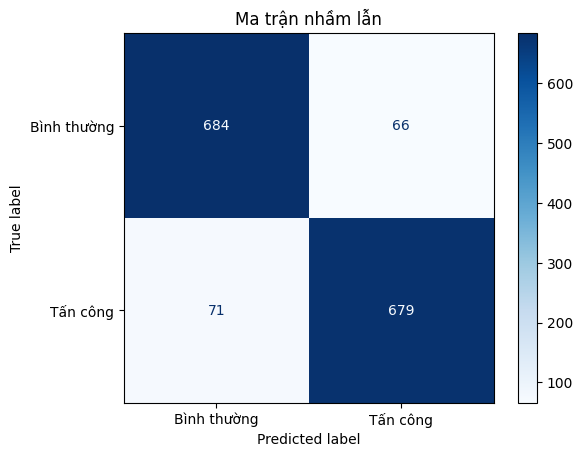

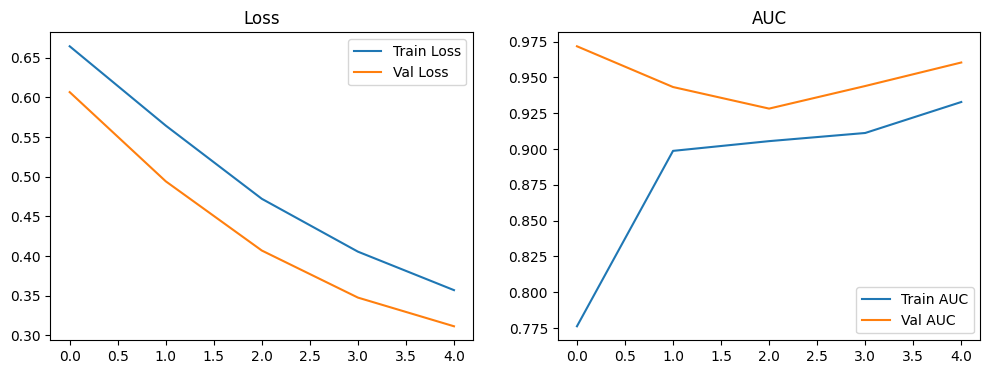

In [10]:

# ═══════════════════════════════════════════════════════════════════════════════
# 9. TEST SET EVALUATION
# ═══════════════════════════════════════════════════════════════════════════════
y_test_prob = stacking_model.predict(
    [X_test_seq, xgb_proba_test], batch_size=BATCH_SIZE
).ravel()
y_test_pred = (y_test_prob >= best_thresh).astype(int)

acc = accuracy_score(y_test, y_test_pred)
bal_acc = balanced_accuracy_score(y_test, y_test_pred)
prec = precision_score(y_test, y_test_pred)
rec = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)
auc = roc_auc_score(y_test, y_test_prob)

print("\n" + "=" * 60)
print("TEST RESULTS")
print("=" * 60)
print(f"Accuracy         : {acc:.4f}")
print(f"Balanced Accuracy: {bal_acc:.4f}")
print(f"Precision        : {prec:.4f}")
print(f"Recall           : {rec:.4f}")
print(f"F1-score         : {f1:.4f}")
print(f"AUC              : {auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test, y_test_pred, target_names=["Benign (0)", "Attack (1)"], digits=4
    )
)

cm = confusion_matrix(y_test, y_test_pred)
tn, fp, fn, tp = cm.ravel()
print(f"\nConfusion Matrix:\n{cm}")
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

# Vẽ ma trận nhầm lẫn
plt.rcParams["font.sans-serif"] = [
    "Arial Unicode MS",
    "DejaVu Sans",
    "SimHei",
    "sans-serif",
]
plt.rcParams["axes.unicode_minus"] = False
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=["Bình thường", "Tấn công"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Ma trận nhầm lẫn")
plt.show()

# Vẽ đường cong học
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["loss"], label="Train Loss")
axes[0].plot(history.history["val_loss"], label="Val Loss")
axes[0].set_title("Loss")
axes[0].legend()
axes[1].plot(history.history["auc"], label="Train AUC")
axes[1].plot(history.history["val_auc"], label="Val AUC")
axes[1].set_title("AUC")
axes[1].legend()
plt.show()